# Лабораторная работа 1. BPE и Unigram токенизаторы с нуля (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 1:** языковое моделирование и токенизация

**Цель.** Понять токенизацию как задачу сжатия и оценить, как выбор токенизатора влияет на последующую модель.

**Что нужно сдать:**
1. Реализацию byte-level BPE и Unigram LM токенизаторов без сторонних библиотек (кроме `re`, `collections`, `math`).
2. Тесты корректности: \(\mathrm{decode}(\mathrm{encode}(x)) = x\) на всём корпусе и на произвольных байтах.
3. Сравнение с `sentencepiece` (совпадение сегментаций, скорость).
4. Графики «размер словаря — степень сжатия» для русского и английского корпусов и ответы на вопросы.

**Теория, которую нужно уметь воспроизвести на защите.** BPE — жадный алгоритм сжатия: на каждом шаге в словарь добавляется пара символов с наибольшей частотой. Unigram LM задаёт вероятностную модель сегментации
\[
$p(x) = \sum_{s \in S(x)} \prod_{i} p(s_i) $
\],
где \(S(x)\) — множество разбиений строки на подслова. Параметры оцениваются EM-алгоритмом: E-шаг вычисляет ожидаемые числа вхождений подслов через прямой и обратный проход (forward-backward), M-шаг нормирует их. Кодирование — поиск самой вероятной сегментации алгоритмом Витерби.

In [1]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.11.0+cu128, device=cuda, FAST_DEV_RUN=True


## 0. Данные

Используем два корпуса: англоязычный (Tiny Shakespeare) и русскоязычный («Война и мир»). В режиме `FAST_DEV_RUN` корпуса обрезаются.

In [2]:
en_text = load_shakespeare()
ru_text = load_russian()
LIMIT = 200_000 if FAST_DEV_RUN else 2_000_000
en_text, ru_text = en_text[:LIMIT], ru_text[:LIMIT]
print(len(en_text), len(ru_text))
print(ru_text[5000:5300])

200000 200000
ступом согласие прусского короля. Вы так красноречивы. Вы дадите мне чаю?
- Сейчас. A propos,- прибавила она, опять успокоиваясь,- нынче у меня два очень интересные человека,  le vicomte de Mortemart, il est allié aux Montmorency par les Rohans, одна из лучших фамилий Франции. Это один из хороших эм


## 1. Byte-level BPE

Алгоритм обучения:
1. Разбить текст на «предтокены» регулярным выражением (слова с ведущим пробелом, числа, пунктуация), чтобы слияния не пересекали границы слов.
2. Представить каждый предтокен как последовательность байтов UTF-8 (идентификаторы 0–255).
3. Повторять `vocab_size - 256` раз: найти самую частую соседнюю пару, создать новый токен, заменить все вхождения пары.

Наивный пересчёт всех пар на каждом шаге стоит \(O(\text{корпус})\), поэтому храните счётчики пар и индекс «пара → предтокены, где она встречается», обновляя их только для затронутых предтокенов.

In [3]:
import re
from collections import Counter, defaultdict

PRETOKEN_RE = re.compile(r" ?[^\W\d_]+| ?\d{1,3}| ?[^\s\w]+| ?_+|\s+(?!\S)|\s+", re.UNICODE)

def pretokenize(text):
    return PRETOKEN_RE.findall(text)

assert "".join(pretokenize("Hello, мир! 12345  x")) == "Hello, мир! 12345  x"
print(pretokenize("Hello, мир! 12345  x"))

['Hello', ',', ' мир', '!', ' 123', '45', ' ', ' x']


In [4]:
def merge_word(word, pair, new_id):
    """Заменяет все вхождения pair в кортеже word на new_id (слева направо, без перекрытий)."""
    out = []
    i = 0
    while i < len(word):
        if word[i:i+len(pair)] == pair:
            out.append(new_id)
            i += len(pair)
        else:
            out.append(word[i])
            i += 1

    return tuple(out)

assert merge_word((1, 2, 3, 1, 2), (1, 2), 9) == (9, 3, 9)
assert merge_word((1, 1, 1), (1, 1), 7) == (7, 1)

In [6]:
class ByteBPE:
    def __init__(self):
        self.merges = {}                       # (a, b) -> new_id, порядок вставки = ранг
        self.vocab = {i: bytes([i]) for i in range(256)}
        self._cache = {}

    def train(self, text, vocab_size, verbose=False):
        assert vocab_size >= 256
        words = Counter(tuple(t.encode("utf-8")) for t in pretokenize(text))
        word_list = list(words.keys()); counts = [words[w] for w in word_list]

        # TODO: ваш код (счётчик пар + индекс pair -> множество номеров слов, инкрементальное обновление)
        
        pair_counts = Counter()
        where = defaultdict(set)
        for idx, w in enumerate(word_list):
            for p in zip(w, w[1:]):
                pair_counts[p] += counts[idx] # pair_counts:  (a,b)=1+2+1=4   ( ,a)=2+1=3   (b,c)=1
                where[p].add(idx) #where: (a,b)→{0,1,2}   ( ,a)→{1,2}   (b,c)→{2}
        
        # 2. Делаем vocab_size - 256 слияний; одна итерация = одна склейка
        for new_id in range(256, vocab_size):
            if not pair_counts:
                break                                      # склеивать больше нечего
            best = max(pair_counts, key=pair_counts.get)   # самая частая пара
            a, b = best
            self.merges[best] = new_id # merges[(a,b)] = 256
            self.vocab[new_id] = self.vocab[a] + self.vocab[b] #vocab[256] = byte'a' + byte'b' = byte'ab'
            if verbose and new_id % 100 == 0:
                print(new_id, self.vocab[new_id], pair_counts[best])

            # 3. Пересчитываем только слова, в которых есть best
            # мы трогаем только слова, где была пара best, и узнаём их из индекса where - «инкрементальное обновление».
            for idx in where.pop(best, ()):
                w, c = word_list[idx], counts[idx]
                for p in zip(w, w[1:]):                    # убираем старые пары слова
                    pair_counts[p] -= c
                    if pair_counts[p] <= 0:
                        del pair_counts[p]
    # Вычитаем все старые пары слова с его весом "c". Если счётчик упал до нуля, удаляем пару совсем, чтобы max её не выбрал.
                nw = merge_word(w, best, new_id)           # склеиваем
                word_list[idx] = nw
    # Склеиваем пару в слове функцией, которую писали выше, и записываем новое слово на место старого.
                for p in zip(nw, nw[1:]):                  # добавляем новые пары
                    pair_counts[p] += c
                    where[p].add(idx)
            pair_counts.pop(best, None)
        self._cache = {}
        return self

    def _encode_chunk(self, chunk): # кодирование одного слова, т.е нужно взять новое слово и порезать его точно также как в train
        if chunk in self._cache: return self._cache[chunk]
        ids = tuple(chunk.encode("utf-8"))
        # TODO: ваш код (применяйте слияния в порядке их ранга (номера), пока есть применимые пары)
        
        while len(ids) >= 2: # Среди всех соседних пар ищем ту, у которой самый маленький номер в merges, то есть выученную раньше всех. Если пары нет в merges, .get возвращает бесконечность, и такая пара никогда не победит.
            pair = min(zip(ids, ids[1:]), key=lambda p: self.merges.get(p, float("inf")))
            if pair not in self.merges:
                break                                      # Если даже лучшая пара не выучена (её ранг равен бесконечности), склеивать больше нечего и мы выходим. 
            ids = merge_word(ids, pair, self.merges[pair]) # Иначе склеиваем и повторяем.
        self._cache[chunk] = list(ids)
        return list(ids)
    
    def encode(self, text):
        out = []
        for ch in pretokenize(text): out.extend(self._encode_chunk(ch))
        return out

    def decode(self, ids):
        # TODO: ваш код
        return b"".join(self.vocab[i] for i in ids).decode("utf-8", errors="replace")
    # превращаем список индексов в байты, а потом декодируем в строку.
    # Каждый id превращаем в его байты: [258, 33] → b' abc', b'!'.
    # Склеиваем все байты в одну строку байтов: b' abc!'.
    # Превращаем байты в текст.


t0 = time.time()
bpe_en = ByteBPE().train(en_text, 1000)
print(f"обучение: {time.time() - t0:.1f} c, токенов в словаре: {len(bpe_en.vocab)}")
print([bpe_en.vocab[i] for i in list(bpe_en.vocab)[256:276]])

обучение: 0.2 c, токенов в словаре: 1000
[b' t', b'he', b'ou', b' a', b' s', b' w', b're', b'ha', b' the', b'in', b' m', b'nd', b' b', b'er', b'it', b'is', b'or', b'on', b'll', b'es']


### Тесты корректности

Проверьте обратимость на всём корпусе, на тексте на другом языке, на эмодзи и на случайных байтах, декодированных как UTF-8 с заменой.

In [7]:
def check_roundtrip(tok, text):
    return tok.decode(tok.encode(text)) == text

assert check_roundtrip(bpe_en, en_text)
assert check_roundtrip(bpe_en, ru_text[:20000])
assert check_roundtrip(bpe_en, "Ёжик 🦔 и 数学 — test\t\n  ")
rnd = bytes(np.random.randint(0, 256, 5000).tolist()).decode("utf-8", errors="replace")
assert check_roundtrip(bpe_en, rnd)
print("Все тесты обратимости пройдены")

Все тесты обратимости пройдены


## 2. Unigram LM токенизатор

Работаем на уровне символов Unicode, пробел заменяем на `▁` и присоединяем к началу слова (как в SentencePiece).

1. **Начальный словарь:** все символы корпуса + самые частые подстроки длины 2…`max_len` (в несколько раз больше целевого размера).
2. **E-шаг:** для каждого слова прямой проход $$\alpha_j = \log \sum_{i<j} \exp\left(\alpha_i + \log p(x_{i:j})\right)$$, обратный проход $$\beta_i = \log \sum_{j>i} \exp\left(\log p(x_{i:j}) + \beta_j\right)$$; ожидаемое число вхождений подслова $$\mathbb{E}[\operatorname{count}(x_{i:j})]=\exp\left(\alpha_i + \log p(x_{i:j}) + \beta_j - \log Z\right)\cdot f(w)$$, умноженное на частоту слова.
3. **M-шаг:** $$p(s) = \frac{\mathbb{E}[\operatorname{count}(s)]}
{\sum_{s' \in V} \mathbb{E}[\operatorname{count}(s')]}$$.
4. **Прунинг:** удалить долю подслов с наименьшей вероятностью (одиночные символы не удалять), повторять до целевого размера словаря.

Это упрощённая версия: SentencePiece удаляет подслова по приросту правдоподобия корпуса при их удалении, а не по вероятности.

In [8]:
def logsumexp2(a, b):
    if a == -math.inf: return b
    if b == -math.inf: return a
    m = max(a, b); return m + math.log(math.exp(a - m) + math.exp(b - m))

def words_of(text):
    return Counter("▁" + w for w in text.split())

class UnigramTokenizer:
    def __init__(self, max_len=8):
        self.max_len = max_len; self.logp = {}

    def _forward_backward(self, w):
        """Возвращает (logZ, словарь ожидаемых вхождений подслов) для одного слова."""
        n = len(w) 
        L = self.max_len
        lp = self.logp

        # TODO: ваш код
        # Прямой проход 
        alpha = [-math.inf] * (n + 1) # log(0) = -inf
        alpha[0] = 0.0
        for j in range(1, n + 1):
            for i in range(max(0, j - L), j):
                s = w[i:j]
                if s in lp:
                    alpha[j] = logsumexp2(alpha[j], alpha[i] + lp[s])

        # обратный проход: beta[i] = log суммы вероятностей всех нарезок w[i:]
        beta = [-math.inf] * (n + 1); beta[n] = 0.0
        for i in range(n - 1, -1, -1):
            for j in range(i + 1, min(n, i + L) + 1):
                s = w[i:j]
                if s in lp:
                    beta[i] = logsumexp2(beta[i], lp[s] + beta[j])
        logZ = alpha[n]
        
        # ожидаемое число использований каждого подслова
        counts = defaultdict(float)
        for i in range(n):
            for j in range(i + 1, min(n, i + L) + 1):
                s = w[i:j]
                if s in lp:
                    counts[s] += math.exp(alpha[i] + lp[s] + beta[j] - logZ)
        
        return logZ, counts



    def train(self, text, vocab_size, init_factor=4, prune_frac=0.2, em_iters=2, verbose=True):
        words = words_of(text)
        chars = Counter(); subs = Counter()
        for w, c in words.items():
            for ch in w: chars[ch] += c
            for i in range(len(w)):
                for j in range(i + 2, min(len(w), i + self.max_len) + 1):
                    subs[w[i:j]] += c
        init = dict(chars); init.update(dict(subs.most_common(init_factor * vocab_size)))
        total = sum(init.values()); self.logp = {s: math.log(c / total) for s, c in init.items()}
        self.chars = set(chars)
        while True:
            for _ in range(em_iters):
                # TODO: ваш код (E-шаг по всем словам с весом частоты, затем M-шаг; накопите log-правдоподобие)
                # E-шаг
                exp_counts = defaultdict(float); ll = 0.0
                for w, c in words.items():
                    logZ, ec = self._forward_backward(w)
                    ll += c * logZ
                    for s, v in ec.items():
                        exp_counts[s] += c * v
                # M-шаг: новые вероятности = нормированные ожидаемые числа
                total = sum(exp_counts.values())             # знаменательпо всему словарю

                new_logp = {}
                for s in self.logp:    # перебираем все подслова текущего словаря
                    count = exp_counts.get(s, 0.0)  # числитель
                    if count > 0 or s in self.chars:  # фильтр: кого оставляем
                        p = max(count, 1e-12) / total   
                        new_logp[s] = math.log(p)
                self.logp = new_logp
                # Кладём в словарь log(p(s)), потому что все остальные функции работают с логарифмами вероятностей.

            if verbose: print(f"|V|={len(self.logp):6d}  log-likelihood={ll:.4e}")
            if len(self.logp) <= vocab_size: break
            # TODO: ваш код (удалите prune_frac наименее вероятных подслов длины > 1, не опускаясь ниже vocab_size)
            # прунинг: удаляем наименее вероятные подслова длины > 1
            cands = sorted((s for s in self.logp if len(s) > 1), key=self.logp.get)
            k = min(max(1, int(prune_frac * len(self.logp))),
                    len(self.logp) - vocab_size, len(cands))
            for s in cands[:k]:
                del self.logp[s]
        return self


    def segment(self, w):
        """Витерби: самая вероятная сегментация слова."""
        # TODO: ваш код
        n = len(w); L = self.max_len; lp = self.logp
        best = [-math.inf] * (n + 1); best[0] = 0.0
        back = [0] * (n + 1)
        for j in range(1, n + 1):
            for i in range(max(0, j - L), j):
                s = w[i:j]
                if s in lp:
                    score = lp[s]
                elif j - i == 1:
                    score = -1e9                 # неизвестный символ: огромный штраф
                else:
                    continue
                if best[i] + score > best[j]:
                    best[j] = best[i] + score
                    back[j] = i
        pieces = []; j = n
        while j > 0:
            i = back[j]; pieces.append(w[i:j]); j = i
        return pieces[::-1]

    def encode(self, text):
        # Сохраняем точную обратимость: пробельные символы кодируются отдельными «токенами»
        out = []
        for part in re.split(r"(\s+)", text):
            if not part: continue
            if part.isspace():
                if part == " ": continue           # одиночный пробел кодируется префиксом ▁ следующего слова
                out.append(part)
            else:
                out.extend(self.segment("▁" + part))
        return out

    def decode(self, pieces):
        s, prev_ws = "", True
        for p in pieces:
            if p.startswith("▁"):
                s += ("" if prev_ws else " ") + p[1:]; prev_ws = False
            else:
                s += p; prev_ws = p.isspace()
        return s

t0 = time.time()
uni_en = UnigramTokenizer().train(en_text[: (60_000 if FAST_DEV_RUN else 500_000)], 1000)
print(f"обучение: {time.time() - t0:.1f} c")
print(uni_en.encode("To be, or not to be: that is the question."))

|V|=  4058  log-likelihood=-1.1196e+05
|V|=  3247  log-likelihood=-1.0939e+05
|V|=  2598  log-likelihood=-1.0916e+05
|V|=  2079  log-likelihood=-1.0906e+05
|V|=  1664  log-likelihood=-1.0905e+05
|V|=  1332  log-likelihood=-1.0987e+05
|V|=  1066  log-likelihood=-1.1133e+05
|V|=  1000  log-likelihood=-1.1168e+05
обучение: 1.4 c
['▁To', '▁be', ',', '▁or', '▁not', '▁to', '▁be', ':', '▁that', '▁is', '▁the', '▁qu', 'es', 'tion', '.']


**Замечание об обратимости.** Наш Unigram-токенизатор работает с токенами-строками, а не с байтами. Обратимость гарантирована для текстов из одиночных пробелов между словами; проверьте её на корпусе, нормализованном так, как это делает SentencePiece (подряд идущие пробелы сжаты, переводы строк сохранены).

In [9]:
def normalize_spaces(t):
    t = re.sub(r"[ \t]+", " ", t)
    return re.sub(r" *\n *", "\n", t).strip()

sample = normalize_spaces(en_text[:20000])
assert uni_en.decode(uni_en.encode(sample)) == sample
print("Unigram: обратимость на нормализованном корпусе выполнена")

Unigram: обратимость на нормализованном корпусе выполнена


## 3. Сравнение с SentencePiece

Обучите `sentencepiece` в режимах `bpe` и `unigram` с тем же размером словаря и сравните:
- долю слов, сегментированных одинаково с вашей реализацией;
- среднее число токенов на слово;
- время обучения и кодирования.

Полного совпадения ожидать не нужно: SentencePiece использует другой прунинг, нормализацию и обработку редких символов.

In [10]:
try:
    import sentencepiece as spm
except ImportError:
    os.system("pip -q install sentencepiece"); import sentencepiece as spm

corpus_file = DATA / "en_corpus.txt"; corpus_file.write_text(en_text, encoding="utf-8")
spm_models = {}
for mtype in ("bpe", "unigram"):
    t0 = time.time()
    spm.SentencePieceTrainer.train(input=str(corpus_file), model_prefix=str(ARTIFACTS / f"spm_{mtype}"),
                                   vocab_size=1000, model_type=mtype, character_coverage=1.0,
                                   max_sentence_length=100000, minloglevel=2)
    spm_models[mtype] = spm.SentencePieceProcessor(model_file=str(ARTIFACTS / f"spm_{mtype}.model"))
    print(mtype, f"обучение {time.time() - t0:.1f} c")

bpe обучение 0.1 c
unigram обучение 0.2 c


In [11]:
def agreement(seg_a, seg_b, words):
    same = sum(seg_a(w) == seg_b(w) for w in words)
    return same / len(words)

test_words = [w for w, _ in words_of(en_text[150_000:]).most_common(2000)]
ours_uni = lambda w: uni_en.segment(w)
sp_uni = lambda w: [p for p in spm_models["unigram"].encode(w[1:], out_type=str)]
ours_bpe = lambda w: [bpe_en.vocab[i].decode("utf-8", "replace") for i in bpe_en.encode(" " + w[1:])]
sp_bpe = lambda w: [p.replace("▁", " ") for p in spm_models["bpe"].encode(w[1:], out_type=str)]

# TODO: ваш код (посчитайте agreement, токены на слово и время кодирования для четырёх токенизаторов)
toks = {"ours_bpe": ours_bpe, "sp_bpe": sp_bpe,
        "ours_uni": ours_uni, "sp_uni": sp_uni}

bpe_en._cache = {}            # сбрасываем кеш, иначе наш BPE «читерит» по времени
rows = []
for name, f in toks.items():
    t0 = time.time()
    segs = [f(w) for w in test_words]                 # кодируем все тестовые слова
    dt = time.time() - t0
    tpw = sum(len(s) for s in segs) / len(test_words) # токенов на слово
    rows.append((name, tpw, dt * 1000))

print(f"{'токенизатор':10s} {'ток/слово':>10s} {'время, мс':>10s}")
for name, tpw, ms in rows:
    print(f"{name:10s} {tpw:10.3f} {ms:10.1f}")

print(f"\nagreement BPE     (наш vs SP): {agreement(ours_bpe, sp_bpe, test_words):.3f}")
print(f"agreement Unigram (наш vs SP): {agreement(ours_uni, sp_uni, test_words):.3f}")

# несколько примеров расхождений — пригодятся для отчёта
print("\nПримеры, где Unigram расходится:")
diff = [w for w in test_words if ours_uni(w) != sp_uni(w)][:8]
for w in diff:
    print(f"  {w:14s} наш={ours_uni(w)}  SP={sp_uni(w)}")

токенизатор  ток/слово  время, мс
ours_bpe        3.151       18.5
sp_bpe          2.872        6.2
ours_uni        2.868       10.0
sp_uni          2.919        4.2

agreement BPE     (наш vs SP): 0.728
agreement Unigram (наш vs SP): 0.366

Примеры, где Unigram расходится:
  ▁GLOUCESTER:   наш=['▁G', 'L', 'O', 'U', 'C', 'E', 'S', 'T', 'E', 'R', ':']  SP=['▁G', 'L', 'O', 'U', 'CE', 'ST', 'ER', ':']
  ▁Murderer:     наш=['▁M', 'ur', 'd', 'er', 'er', ':']  SP=['▁Murder', 'er', ':']
  ▁LADY          наш=['▁L', 'A', 'D', 'Y']  SP=['▁LADY']
  ▁ANNE:         наш=['▁A', 'N', 'N', 'E', ':']  SP=['▁', 'AN', 'NE', ':']
  ▁QUEEN         наш=['▁', 'Q', 'U', 'E', 'E', 'N']  SP=['▁QUEEN']
  ▁MARGARET:     наш=['▁M', 'A', 'R', 'G', 'A', 'R', 'E', 'T', ':']  SP=['▁MAR', 'G', 'ARE', 'T', ':']
  ▁CLARENCE:     наш=['▁C', 'L', 'A', 'R', 'E', 'N', 'C', 'E', ':']  SP=['▁CLARE', 'N', 'CE', ':']
  ▁ELIZABETH:    наш=['▁E', 'L', 'I', 'Z', 'A', 'B', 'E', 'T', 'H', ':']  SP=['▁', 'E', 'LI', 'Z', 'A', 'B', 'E', 

## 4. Размер словаря, язык и степень сжатия

Для словарей 1k, 8k, 32k (в `FAST_DEV_RUN`: 300, 1000, 2000) обучите BPE на английском и русском корпусах и измерьте на отложенной части:
- **fertility** — среднее число токенов на слово;
- **сжатие** — байтов UTF-8 на токен;
- **долю редких токенов** — долю токенов словаря, встретившихся в отложенной части менее 5 раз.

Обучающая и отложенная части не должны пересекаться.

In [14]:
from collections import Counter

VOCABS = [300, 1000, 2000] if FAST_DEV_RUN else [1000, 8000, 32000]

def tokenizer_stats(tok, text, vocab_size):

    words = pretokenize(text)

    # токены для всего текста + счётчик частот токенов
    all_ids = []
    for w in words:
        all_ids.extend(tok._encode_chunk(w))

    n_tokens = len(all_ids)
    n_words  = max(len(words), 1)

    # fertility - среднее число токенов на слово
    fertility = n_tokens / n_words

    # сжатие - байтов UTF-8 на токен
    n_bytes = len(text.encode("utf-8"))
    bytes_per_token = n_bytes / max(n_tokens, 1)

    # доля редких токенов словаря, встретившихся < 5 раз
    freq = Counter(all_ids)
    # vocab — все id, которые токенизатор знает (включая 256 базовых байтов и merges)
    # rare - это id, которые либо вообще не встретились, либо встретились < 5 раз
    rare = sum(1 for i in tok.vocab if freq.get(i, 0) < 5)
    rare_share = rare / max(vocab_size, 1)

    return {
        "fertility":       fertility,
        "bytes_per_token": bytes_per_token,
        "rare_share":      rare_share,
        "n_tokens":        n_tokens,
        "n_words":         n_words,
    }

results = {}
for lang, text in [("en", en_text), ("ru", ru_text)]:
    threshold = int(0.8 * len(text))
    train_t, test_t = text[:threshold], text[threshold:]
    for V in VOCABS:
        tok = ByteBPE().train(train_t, V)
        results[(lang, V)] = tokenizer_stats(tok, test_t, len(tok.vocab))
        print(lang, V, {k: round(v, 3) for k, v in results[(lang, V)].items()})

en 300 {'fertility': 2.748, 'bytes_per_token': 1.371, 'rare_share': 0.657, 'n_tokens': 29173, 'n_words': 10615}
en 1000 {'fertility': 1.695, 'bytes_per_token': 2.223, 'rare_share': 0.476, 'n_tokens': 17994, 'n_words': 10615}
en 2000 {'fertility': 1.427, 'bytes_per_token': 2.64, 'rare_share': 0.725, 'n_tokens': 15149, 'n_words': 10615}
ru 300 {'fertility': 4.381, 'bytes_per_token': 1.942, 'rare_share': 0.557, 'n_tokens': 35468, 'n_words': 8096}
ru 1000 {'fertility': 2.196, 'bytes_per_token': 3.875, 'rare_share': 0.394, 'n_tokens': 17776, 'n_words': 8096}
ru 2000 {'fertility': 1.814, 'bytes_per_token': 4.69, 'rare_share': 0.639, 'n_tokens': 14686, 'n_words': 8096}


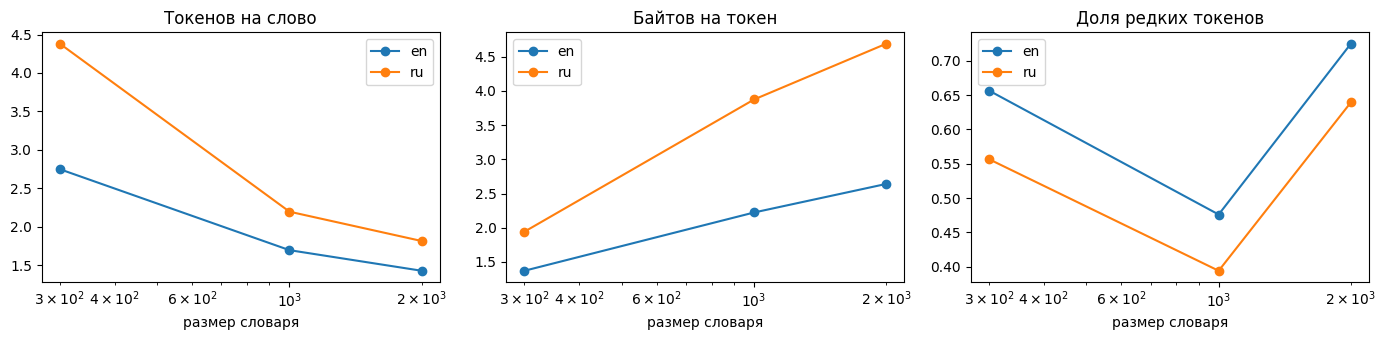

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, key, title in zip(axes, ["fertility", "bytes_per_token", "rare_share"],
                          ["Токенов на слово", "Байтов на токен", "Доля редких токенов"]):
    for lang in ("en", "ru"):
        ax.plot(VOCABS, [results[(lang, V)][key] for V in VOCABS], "o-", label=lang)
    ax.set_xscale("log"); ax.set_xlabel("размер словаря"); ax.set_title(title); ax.legend()
plt.tight_layout(); plt.savefig(ARTIFACTS / "lab01_vocab_curves.png", dpi=120); plt.show()

Больше словарь - лучше сжатие: fertility падает (en 2.75 и 1.43, ru 4.38 и 1.82), bytes/token растёт (en 1.37→2.64, ru 1.94→4.68).

Но растёт балласт: rare_share прыгает на V=2000 (en 0.48 и 0.73, ru 0.40 и 0.65). Оптимум примерно 1000 токенов.

Русский дороже: fertility выше (2.20 vs 1.70) из-за морфологии; bytes/token выше (3.87 vs 2.22), т.к. кириллица = 2 байта/символ в UTF-8.

## 5. Токенизация чисел и кода

Посмотрите, как токенизатор разбивает числа разной длины и фрагменты кода. Найдите примеры, где одно и то же число разбивается по-разному в зависимости от контекста (с пробелом и без), и объясните, почему это мешает модели выполнять арифметику.

In [16]:
examples = ["12345 + 67890 = 80235", "x12345", " 1000000", "3.14159", "def f(x):\n    return x**2"]
for e in examples:
    print(repr(e), "->", [bpe_en.vocab[i].decode("utf-8", "replace") for i in bpe_en.encode(e)])

'12345 + 67890 = 80235' -> ['1', '2', '3', '4', '5', ' ', '+', ' ', '6', '7', '8', '9', '0', ' ', '=', ' ', '8', '0', '2', '3', '5']
'x12345' -> ['x', '1', '2', '3', '4', '5']
' 1000000' -> [' ', '1', '0', '0', '0', '0', '0', '0']
'3.14159' -> ['3', '.', '1', '4', '1', '5', '9']
'def f(x):\n    return x**2' -> ['de', 'f', ' f', '(', 'x', ')', ':', '\n', ' ', ' ', ' ', ' re', 't', 'urn', ' ', 'x', '*', '*', '2']


Разбиение:

* Числа '12345' и с пробелом ' 12345' - то же число, но другое представление.

* Код return, ** - делит не атомарно.

Почему мешает арифметике:

1) Нет выравнивания по разрядам - токен 1 везде одинаков, позиция не видна.
2) Одно число кодируется по-разному в зависимости от контекста.
3) Операторы/ключевые слова разрезаны.

## Вопросы

1. Почему BPE-обучение можно рассматривать как жадный алгоритм сжатия? Что он оптимизирует на каждом шаге и почему результат не оптимален глобально?
2. Почему при одинаковом размере словаря русский текст даёт больше токенов на слово, чем английский? Как это влияет на стоимость инференса и эффективную длину контекста?
3. Чем Unigram LM лучше BPE с вероятностной точки зрения? Что даёт возможность сэмплировать сегментации (subword regularization)?
4. Почему perplexity моделей с разными токенизаторами нельзя сравнивать напрямую и как перейти к bits-per-byte?
5. Предложите способ токенизации чисел, облегчающий арифметику, и обоснуйте его.

Ответы:

1) На каждом шаге выбирает самую частую пару и сливает её - локально оптимально для текущего корпуса
2) Богатая морфология и кириллица = 2 байта/символ в UTF-8. Инференс дороже (больше токенов на тот же текст), эффективный контекст короче (в окно влезает меньше текста)
3) Задаёт вероятностную модель и можно сравнивать сегментации по вероятности. Позволяет сэмплировать сегментации пропорционально вероятности (subword regularization): при обучении одно слово иногда режется по-разному и модель становится устойчивее к вариативности сегментации
4) perplexity зависит от размера словаря и единицы (токен): у BPE и Unigram разные токены. Сравнивать числа бессмысленно. При нормировке на байты можно честно сравнивать модели с разными словарями.
5) Разбивать число на цифры с маркером разряда (1_234_567), выравнивая позиции. Обоснование: сохраняется структура разрядов, один и тот же разряд всегда в одном токене. Дополнительно — отдельные токены для операторов.